# sunset

A soft dusk-blue -> lavender -> peach -> gold ramp, from `sunset.jpg`.

Two versions:

* **`sunset_original`** -- the six stops as first picked, blended in RGB. Kept
  for reference; don't use it for data.
* **`sunset`** -- the same hue path with its lightness made even, blended in
  OKLab. Use this one.

Why the original needed fixing: a sequential map is read by its lightness, and
the original's lightness is lopsided. OKLab L runs 0.52 -> 0.90, and ~80% of
that happens in the blue -> lavender half; the lavender -> pink -> peach ->
yellow half is nearly flat (L 0.85-0.90), separated only by hue. Pale,
low-chroma hue differences are exactly what colour-vision deficiency removes,
so under protan/deutan simulation the warm half collapses to one beige and
under tritan to one pink. The fix keeps the hues and gives the ramp an even
L 0.42 -> 0.90, split equally between its two halves in every vision type.

Caveat: the light end is ~1.4:1 against white, so on a white page trim it
(sample 0-0.9) the way you would trim viridis's yellow.

In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, to_hex

## OKLab helpers

In [2]:
# OKLab (Ottosson 2020). Interpolating here keeps lightness steps even;
# LinearSegmentedColormap blends in sRGB, which does not.
_M1 = np.array([[0.4122214708, 0.5363325363, 0.0514459929],
                [0.2119034982, 0.6806995451, 0.1073969566],
                [0.0883024619, 0.2817188376, 0.6299787005]])
_M2 = np.array([[0.2104542553, 0.7936177850, -0.0040720468],
                [1.9779984951, -2.4285922050, 0.4505937099],
                [0.0259040371, 0.7827717662, -0.8086757660]])

def _lin(c):
    c = np.asarray(c, float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def _gam(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * c ** (1 / 2.4) - 0.055)

def to_oklab(colour):
    return _M2 @ np.cbrt(_M1 @ _lin(matplotlib.colors.to_rgb(colour)))

def from_oklab(lab):
    return _gam(np.linalg.solve(_M1, np.linalg.solve(_M2, lab) ** 3))

def lch(colour):
    L, a, b = to_oklab(colour)
    return L, np.hypot(a, b), np.rad2deg(np.arctan2(b, a)) % 360

def lch_to_hex(L, C, h):
    r = np.deg2rad(h)
    return to_hex(from_oklab([L, C * np.cos(r), C * np.sin(r)]))

def in_gamut(L, C, h):
    r = np.deg2rad(h)
    rgb = np.linalg.solve(_M1, np.linalg.solve(_M2, [L, C * np.cos(r), C * np.sin(r)]) ** 3)
    return bool(np.all(rgb >= -1e-4) and np.all(rgb <= 1 + 1e-4))

def oklab_cmap(name, stops, n=256):
    labs = [to_oklab(s) for s in stops]
    seg = len(labs) - 1
    out = []
    for t in np.linspace(0, 1, n):
        i = min(int(t * seg), seg - 1)
        f = t * seg - i
        out.append(from_oklab((1 - f) * labs[i] + f * labs[i + 1]))
    return ListedColormap(out, name=name)

def register(cmap):
    for c in (cmap, cmap.reversed()):
        if c.name in matplotlib.colormaps:
            matplotlib.colormaps.unregister(c.name)
        matplotlib.colormaps.register(c)

## The original stops

In [3]:
SUNSET_ORIGINAL = ['#54679b', '#8c8ec2', '#baaed3', '#efc4bb', '#ffc9aa', '#ffd79a']

for s in SUNSET_ORIGINAL:
    L, C, h = lch(s)
    print(f"{s}  L {L:.3f}  C {C:.3f}  h {h:5.1f}")

register(LinearSegmentedColormap.from_list("sunset_original", SUNSET_ORIGINAL))

#54679b  L 0.521  C 0.086  h 268.1
#8c8ec2  L 0.665  C 0.077  h 282.4
#baaed3  L 0.773  C 0.054  h 300.0
#efc4bb  L 0.855  C 0.051  h  31.9
#ffc9aa  L 0.876  C 0.074  h  51.3
#ffd79a  L 0.899  C 0.089  h  77.8


## The fixed ramp

Same hue path as the original stops (dusk blue h 268 -> violet -> pink ->
peach -> gold h 78), lightness linear from 0.42 to 0.90, chroma rising from
0.08 to 0.11 so the warm end is not washed out, each stop pulled into sRGB
gamut by lowering chroma.

In [4]:
def build(stops, L0=0.42, L1=0.90, C0=0.08, C1=0.11, n=7):
    hues = np.rad2deg(np.unwrap(np.deg2rad([lch(s)[2] for s in stops])))
    out = []
    for t in np.linspace(0, 1, n):
        h = np.interp(t, np.linspace(0, 1, len(hues)), hues) % 360
        L = L0 + (L1 - L0) * t
        C = C0 + (C1 - C0) * t
        while not in_gamut(L, C, h) and C > 0:
            C -= 0.002
        out.append(lch_to_hex(L, C, h))
    return out

SUNSET = build(SUNSET_ORIGINAL)
print(SUNSET)
# ['#3a4b79', '#5a5d93', '#7d70aa', '#bc7a9f', '#e2957c', '#f9b281', '#ffd79b']

register(oklab_cmap("sunset", SUNSET))

['#3a4b79', '#5a5d93', '#7d70aa', '#bc7a9f', '#e2957c', '#f9b281', '#ffd79b']


## Check it under colour-vision deficiency

Machado, Oliveira & Fernandes 2009 simulation, severity 1.0. For a sequential
map the test is that lightness rises monotonically in every vision type AND is
split evenly between the two halves. The original passes the first and fails
the second (dL 0.27-0.30 in the cool half, 0.07-0.09 in the warm half).
Viridis, for scale: even halves, total dE ~75-80.

In [5]:
_CVD = {
    "protan": np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    "deutan": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "tritan": np.array([[1.255528, -0.076749, -0.178779], [-0.078411, 0.930809, 0.147602], [0.004733, 0.691367, 0.303900]]),
}

def simulate(rgb, kind):
    if kind == "normal":
        return np.asarray(rgb)[:3]
    return _gam(_CVD[kind] @ _lin(np.asarray(rgb)[:3]))

def report(name, n=64):
    cmap = matplotlib.colormaps[name]
    cols = [cmap(t) for t in np.linspace(0, 1, n)]
    print(name)
    for kind in ("normal", "protan", "deutan", "tritan"):
        labs = np.array([_M2 @ np.cbrt(_M1 @ _lin(simulate(c, kind))) for c in cols])
        L = labs[:, 0]
        steps = 100 * np.linalg.norm(np.diff(labs, axis=0), axis=1)
        half = n // 2
        print(f"  {kind:7s} L {L[0]:.2f}->{L[-1]:.2f}  monotone {bool(np.all(np.diff(L) > 0))!s:5}  "
              f"total dE {steps.sum():5.1f}  dL by half {L[half - 1] - L[0]:.2f} / {L[-1] - L[half]:.2f}")

for name in ("sunset_original", "sunset", "viridis"):
    report(name)

sunset_original
  normal  L 0.52->0.90  monotone True   total dE  45.3  dL by half 0.29 / 0.08
  protan  L 0.53->0.88  monotone True   total dE  41.4  dL by half 0.27 / 0.07
  deutan  L 0.51->0.91  monotone True   total dE  45.5  dL by half 0.30 / 0.09
  tritan  L 0.52->0.89  monotone True   total dE  40.9  dL by half 0.29 / 0.07
sunset
  normal  L 0.42->0.90  monotone True   total dE  57.0  dL by half 0.23 / 0.24
  protan  L 0.43->0.88  monotone True   total dE  51.3  dL by half 0.19 / 0.25
  deutan  L 0.41->0.91  monotone True   total dE  55.3  dL by half 0.24 / 0.24
  tritan  L 0.42->0.89  monotone True   total dE  55.5  dL by half 0.24 / 0.22
viridis
  normal  L 0.29->0.92  monotone True   total dE  81.6  dL by half 0.30 / 0.32
  protan  L 0.27->0.90  monotone True   total dE  73.6  dL by half 0.36 / 0.27
  deutan  L 0.28->0.92  monotone True   total dE  73.8  dL by half 0.31 / 0.33
  tritan  L 0.28->0.91  monotone True   total dE  75.3  dL by half 0.31 / 0.30


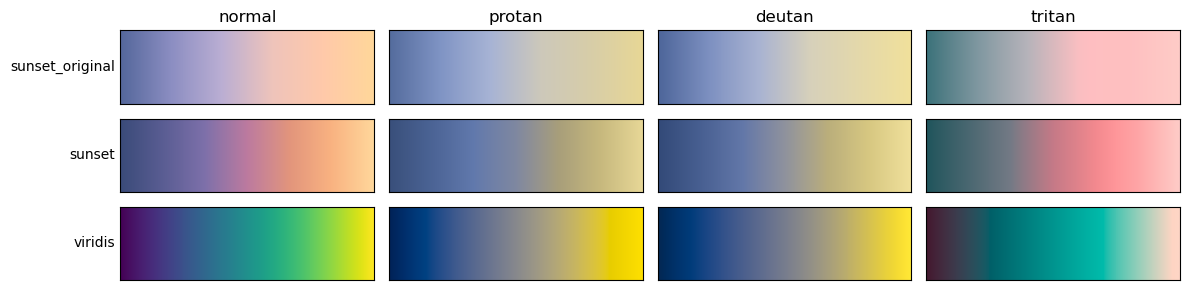

In [6]:
names = ["sunset_original", "sunset", "viridis"]
kinds = ["normal", "protan", "deutan", "tritan"]
fig, axes = plt.subplots(len(names), len(kinds), figsize=(12, 3))
for i, name in enumerate(names):
    cmap = matplotlib.colormaps[name]
    for j, kind in enumerate(kinds):
        strip = np.array([simulate(cmap(t), kind) for t in np.linspace(0, 1, 256)])[None]
        ax = axes[i, j]
        ax.imshow(strip, aspect="auto", interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(kind)
        if j == 0: ax.set_ylabel(name, rotation=0, ha="right", va="center")
fig.tight_layout()
fig.savefig("sunset_cvd.png", dpi=150)

## Swatch

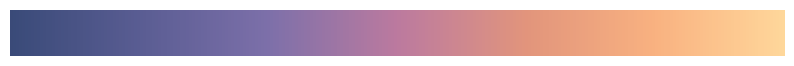

In [7]:
fig, ax = plt.subplots(figsize=(10, 0.6))
ax.imshow(np.linspace(0, 1, 256)[None], aspect="auto", cmap="sunset")
ax.set_axis_off()
fig.savefig("sunset_palette.png", dpi=150, bbox_inches="tight")